# Week 6 Task 2: the LEAP JCM notebook, sections 1–2b (drier soil)

Sections 1–2b of LEAP's hackathon notebook
[`01_jcm_sensitivities.ipynb`](https://github.com/leap-stc/diff-earth/blob/main/2026_hackathon/notebooks/01_jcm_sensitivities.ipynb),
run on our pinned JCM, then a comparison of the forward-mode estimate (2b) with the finite difference (2a), and
experiments that explain why they differ in size.

**Answer.**

- **Sections 1–2b run on our JCM** after one rename (`surface_flux.evap.0` → `surface_flux.evap`). A 7-day run takes
  3.3 s and the 6-hour jvp 6.5 s on a laptop CPU, after compiling.
- **The two differ in size by a factor of 1.23 (land mean).** Scaled to 1% drying, the finite difference (2a ÷ 50)
  is −1.80e-4 g m⁻² s⁻¹ and the jvp (2b) is −1.47e-4. Their maps also differ (pattern correlation 0.62).
- **Why: 2a and 2b are not the same question.** 2a uses a 50% step over 7 days; 2b is an infinitesimal step over
  6 hours. Changing one thing at a time:
  - **Step size explains most of it.** At 6 h, a central 1% difference matches the jvp to 1%, but halving the soil
    gives 1.28× the linear prediction. Evaporation is concave in soil moisture: drying cuts it by more than the
    gradient predicts.
  - **The cause is the skin-temperature energy balance, not the evaporation hinge.** Less evaporation means less
    evaporative cooling, so the skin warms and evaporation partly recovers. This feedback cancels 80% of the direct
    response at 6 h, and it weakens as the soil dries. With it switched off (`lskineb = False`), halving gives
    1.015× the linear prediction. The max(0, ·) hinge accounts for only 0.3% of the gap from this start.
  - **The window changes the size a little and the pattern a lot.** The jvp per 1% falls by 10% from 6 h to 7 days, so
    the factor 1.23 ≈ 1.37 (50% step at 7 days) × 0.90 (7-day vs 6-hour jvp). The 7-day maps concentrate on tropical
    and summer-hemisphere land.
  - **Chaos sets in between 4 and 7 days.** The 1% finite-difference map matches the jvp map with correlation
    ≥ 0.90 up to 4 days, and 0.33 at 7 days.
- **Two more things the course page asked us to look for:**
  - **The hinge appears from a spun-up state.** Section 1 starts from rest, and after 6 hours the air is still dry
    (land evaporation is twice its day-7 value), so almost every land cell is evaporating. Starting from day 7
    instead, 300 land cells have exactly zero gradient (no evaporation), and wetting by 1% switches evaporation on in
    them. These cells explain all of the 30% gap on the wetting side.
  - **float32 round-off appears at the smallest step.** At h = 0.001 the finite difference is 2–3% off, against
    1% at h = 0.003–0.1, as Task 1's error curve predicts.

Figures: `figures/week6_task2_{step_size,hinge,window,maps}.png`. Maps: `results/w6-task2_soil.nc`. Kernel `jcm-model`,
about 2 minutes on a laptop CPU.

Changes from the hackathon notebook, needed for our JCM (`jax-gcm@f378069`):

- `surface_flux.evap.0` is `surface_flux.evap` (dims `time, lon, lat`, units g m⁻² s⁻¹, the `fmask`-weighted
  land/sea mean).
- Section 3's imports (`Parameters`, `speedy_physics`) are dropped. `load_states_from_xarray` is kept for section 5.
- Run times are printed for the second (compiled) call.

In [1]:
from importlib.resources import files
import time

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

from jcm.model import Model as SpeedyModel
from jcm.forcing import ForcingData
from jcm.terrain import TerrainData
from jcm import load_states_from_xarray
from jcm.physics.speedy.speedy_coords import get_speedy_coords

import warnings
warnings.filterwarnings("ignore")
print(jax.__version__, jax.devices())

0.10.2 [CpuDevice(id=0)]


## 1. Model setup and a seven-day run

T31, 8 levels, 30-minute time step, jcm's packaged T30 climatology. The run starts from rest on 1 January.

In [2]:
# Spectral T31 grid with 8 vertical levels
coords = get_speedy_coords(spectral_truncation=31, layers=8)

# Load the terrain and climatological boundary forcing shipped with jcm
data = files("jcm") / "data/bc/t30/clim"
terrain = TerrainData.from_file(data / "terrain.nc", coords=coords)
bc = ForcingData.from_file(data / "forcing.nc", coords=coords, align_mode="wrap_year")

# Initialize model
model = SpeedyModel(
    coords = coords,
    terrain = terrain, # init terrain (e.g., orography, land mask, etc)
    time_step = 30 # model timestep in minutes
)

In [3]:
# Run model (twice: the first call compiles)
for call in (1, 2):
    t = time.time()
    result = model.run(
        forcing = bc,
        total_time = 7, # total model integration time in days
        save_interval = 0.5 # save snapshot in days
    )
    ds = result.to_xarray()
    print(f"7-day run, call {call}: {time.time() - t:.1f} s")

7-day run, call 1: 8.7 s


7-day run, call 2: 3.3 s


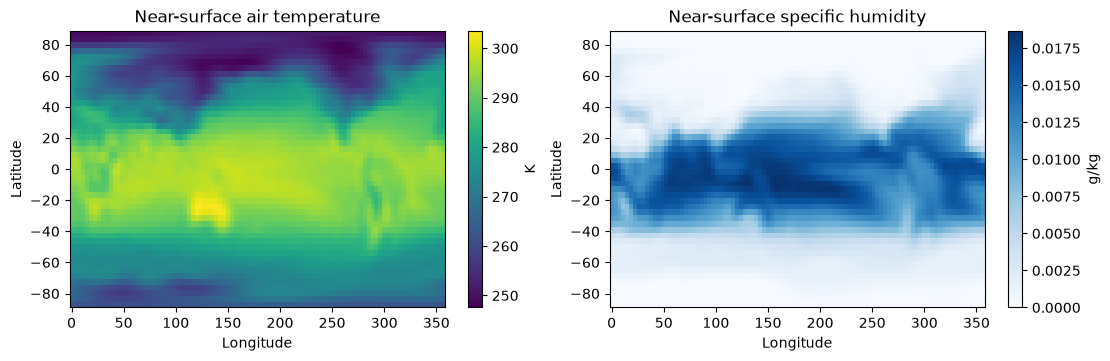

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), constrained_layout=True)

# Plot near-surface T at final timestep
ds.temperature.isel(time=-1, level=0).plot(ax=axes[0], x="lon", y="lat", cmap="viridis", cbar_kwargs={"label": "K"})
axes[0].set(title="Near-surface air temperature", xlabel="Longitude", ylabel="Latitude")

# Plot near-surface q at final timestep
ds.specific_humidity.isel(time=-1, level=0).plot(ax=axes[1], x="lon", y="lat", cmap="Blues", cbar_kwargs={"label": "g/kg"})
axes[1].set(title="Near-surface specific humidity", xlabel="Longitude", ylabel="Latitude");

## 2a. Boundary condition: drier soil (finite difference)

`soilw_am` is the soil moisture availability (0–1), one field per day of the year. Halve it everywhere and for
every day, run seven days from the same start, and difference evaporation against the baseline.

In [5]:
# Soil moisture availability: (day of year, longitude, latitude)
bc.soilw_am.values.shape

(365, 96, 48)

In [6]:
# Halving soil moisture
dry_bc = bc.copy(
    soilw_am=bc.soilw_am.replace(values=0.5 * bc.soilw_am.values)
)

# Run
dry = model.run(
    forcing = dry_bc,
    total_time = 7,
    save_interval = 0.5
)

dry_ds = dry.to_xarray()

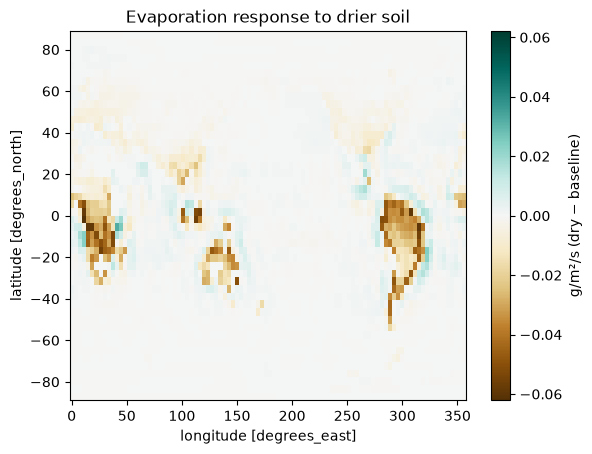

In [7]:
# Plot evaporation response to drier soil
(dry_ds["surface_flux.evap"] - ds["surface_flux.evap"]).isel(time=-1).plot(
    x="lon", y="lat", cmap="BrBG", center=0,
    cbar_kwargs={"label": "g/m²/s (dry − baseline)"}
)
plt.title("Evaporation response to drier soil");

## 2b. Forward mode (JVP): evaporation after 6 hours, 1% drier soil

Evaporation after six hours as a function of one scalar, `soil_scale`, that multiplies the soil moisture field.
`jax.jvp(evaporation, (1.0,), (-0.01,))` gives the linear estimate of the change for 1% drying at every grid point.

In [8]:
def evaporation(soil_scale):
    forcing = bc.copy(soilw_am=bc.soilw_am.replace(values=soil_scale * bc.soilw_am.values))
    model = SpeedyModel(coords=coords, terrain=terrain, time_step=30)
    result = model.run(forcing=forcing, total_time=0.25, save_interval=0.25) # six-hour run
    ds = result.to_xarray()
    return ds["surface_flux.evap"].isel(time=-1).data

In [9]:
# Start at the original BC; calculate the response to 1% drying.
for call in (1, 2):
    t = time.time()
    _, soil_sensitivity = jax.jvp(evaporation, (1.0,), (-0.01,))
    soil_sensitivity.block_until_ready()
    print(f"jvp, 6 h, call {call}: {time.time() - t:.1f} s")

jvp, 6 h, call 1: 6.8 s


jvp, 6 h, call 2: 6.4 s


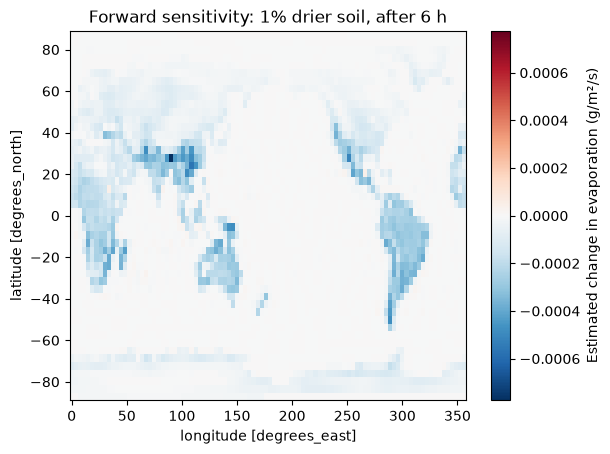

In [10]:
# Plot
soil_map = ds["surface_flux.evap"].isel(time=-1).copy(data=np.asarray(soil_sensitivity))
soil_map.plot(
    x="lon", y="lat", cmap="RdBu_r", center=0,
    cbar_kwargs={"label": "Estimated change in evaporation (g/m²/s)"},
)
plt.title("Forward sensitivity: 1% drier soil, after 6 h");

## 3. Comparing 2a and 2b

The task asks why the two differ in size. To put them on the same scale, divide 2a's response by 50: if evaporation
were linear in soil moisture and the response didn't depend on time, halving (−50%) would give 50 times the
response to −1%. Land means are cos(lat)-weighted over cells with land fraction > 0.5 (1,856 cells have any land;
the mask below is the mostly-land ones). 1 g m⁻² s⁻¹ = 86.4 mm/day.

In [11]:
fmask = np.asarray(terrain.fmask)
land = fmask > 0.5
W = np.broadcast_to(np.cos(np.deg2rad(ds.lat.values)), land.shape)

def land_mean(x):
    x = np.asarray(x)
    return float((x * W)[land].sum() / W[land].sum())

evap0_7d = ds["surface_flux.evap"].isel(time=-1).values
fd_2a = (dry_ds["surface_flux.evap"] - ds["surface_flux.evap"]).isel(time=-1).values
jvp_2b = np.asarray(soil_sensitivity)

print(f"{land.sum()} land cells (fmask > 0.5)")
print(f"baseline land-mean evaporation, day 7:   {land_mean(evap0_7d):.5f} g/m²/s ({86.4 * land_mean(evap0_7d):.2f} mm/day)")
print(f"2a: halving, 7 days                      {land_mean(fd_2a):+.2e} g/m²/s")
print(f"2a / 50 (per 1%, if linear)              {land_mean(fd_2a) / 50:+.2e}")
print(f"2b: jvp, 1% drier, 6 h                   {land_mean(jvp_2b):+.2e}")
print(f"ratio (2a / 50) / 2b                     {land_mean(fd_2a) / 50 / land_mean(jvp_2b):.2f}")
print(f"largest |cell| change: 2a/50 {np.abs(fd_2a[land]).max() / 50:.1e}, 2b {np.abs(jvp_2b[land]).max():.1e}")

1528 land cells (fmask > 0.5)
baseline land-mean evaporation, day 7:   0.01482 g/m²/s (1.28 mm/day)
2a: halving, 7 days                      -9.02e-03 g/m²/s
2a / 50 (per 1%, if linear)              -1.80e-04
2b: jvp, 1% drier, 6 h                   -1.47e-04
ratio (2a / 50) / 2b                     1.23
largest |cell| change: 2a/50 1.2e-03, 2b 7.8e-04


2a and 2b differ in **three** ways at once, so the ratio above mixes three effects:

| | 2a | 2b |
|---|---|---|
| Size of the change | −50% (finite) | −1% (infinitesimal, scaled to 1%) |
| Window | 7 days | 6 hours |
| Method | two nonlinear runs | one forward-mode derivative |

Sections 4–6 change one of these at a time. All runs below use one shared function: the evaporation map at the end of
a window, as a function of the soil-moisture scale factor (and optionally the starting state).

In [12]:
def evap_after(soil_scale, window, initial_state=None):
    """Evaporation (g/m²/s, lon x lat) at the end of `window` days, with soil moisture x soil_scale."""
    forcing = bc.copy(soilw_am=bc.soilw_am.replace(values=soil_scale * bc.soilw_am.values))
    out = model.run(initial_state=initial_state, forcing=forcing, total_time=window, save_interval=window).to_xarray()
    return out["surface_flux.evap"].isel(time=-1).data

def tangent(window, initial_state=None):
    """d(evaporation)/d(soil_scale) at soil_scale = 1, a map. The response to -1% is -0.01 x this."""
    _, t = jax.jvp(lambda s: evap_after(s, window, initial_state), (1.0,), (1.0,))
    return np.asarray(t)

# Check: the shared function reproduces 2b (up to float32 round-off: jvp is linear in the tangent)
t6 = tangent(0.25)
print(f"max |difference| from 2b: {np.abs(-0.01 * t6 - jvp_2b).max():.1e} (largest |2b| value {np.abs(jvp_2b).max():.1e})")

max |difference| from 2b: 1.0e-09 (largest |2b| value 7.8e-04)


## 4. Same 6-hour window: does the size of the step matter?

At 6 hours, compare the derivative with finite differences of different sizes. Central: $[E(1+h) - E(1-h)]/2h$.
Drying only (as in 2a): $[E(1) - E(1-h)]/h$. If evaporation were linear in soil moisture over the step, all would
equal the jvp.

In [13]:
H = [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 0.5]
E0_6h = np.asarray(evap_after(1.0, 0.25))
step = {}
for h in H:
    up, down = np.asarray(evap_after(1.0 + h, 0.25)), np.asarray(evap_after(1.0 - h, 0.25))
    step[h] = dict(central=(up - down) / (2 * h), drying=(E0_6h - down) / h, down=down)

jvp6 = land_mean(t6)
print(f"jvp, 6 h:  {jvp6:.4e} g/m²/s per unit soil_scale")
print(f"{'h':>6} {'central':>11} {'ratio':>6} {'drying':>11} {'ratio':>6}")
for h in H:
    c, d = land_mean(step[h]["central"]), land_mean(step[h]["drying"])
    print(f"{h:6.3f} {c:11.4e} {c / jvp6:6.3f} {d:11.4e} {d / jvp6:6.3f}")

jvp, 6 h:  1.4660e-02 g/m²/s per unit soil_scale
     h     central  ratio      drying  ratio
 0.001  1.5004e-02  1.023  1.5093e-02  1.030
 0.003  1.4777e-02  1.008  1.4823e-02  1.011
 0.010  1.4824e-02  1.011  1.4965e-02  1.021
 0.030  1.4839e-02  1.012  1.5044e-02  1.026
 0.100  1.4831e-02  1.012  1.5415e-02  1.052
 0.300  1.5096e-02  1.030  1.6904e-02  1.153
 0.500  1.5615e-02  1.065  1.8754e-02  1.279


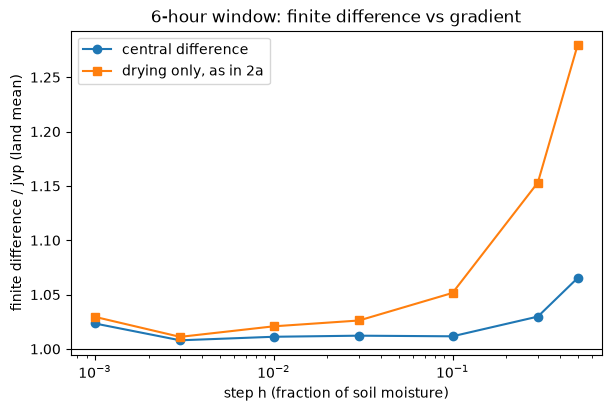

In [14]:
fig, ax = plt.subplots(figsize=(6, 4), constrained_layout=True)
ax.semilogx(H, [land_mean(step[h]["central"]) / jvp6 for h in H], "o-", label="central difference")
ax.semilogx(H, [land_mean(step[h]["drying"]) / jvp6 for h in H], "s-", label="drying only, as in 2a")
ax.axhline(1, color="k", lw=0.8)
ax.set(xlabel="step h (fraction of soil moisture)", ylabel="finite difference / jvp (land mean)",
       title="6-hour window: finite difference vs gradient")
ax.legend()
plt.savefig("../figures/week6_task2_step_size.png", dpi=120)
plt.show()

**At 6 hours, the gradient is right and the response is curved.**

- Central differences from h = 0.003 to 0.1 agree with the jvp to about 1%.
- Drying-only differences drift away as h grows: 1.02 at 1%, 1.05 at 10%, 1.28 at 50%. A drying-only difference
  equals E′ − E″h/2 + …, so a ratio that grows linearly with h means E″ < 0: evaporation is concave in soil
  moisture. The central difference cancels the E″ term, so it stays close until h = 0.5 (1.065, the third-order term).
- At h = 0.001 the error rises again (1.02–1.03). That's float32 round-off: Task 1 put the best central step for
  float32 at a few times 1e-3.

### Where the large-step finite difference departs from the gradient: the evaporation hinge

In SPEEDY's land surface flux (`jcm/physics/surface/speedy_surface_flux.py`), land evaporation is

$$E = c_{hl}\,\rho\,|V|\,\max\big(0,\; w\,q_{sat}(T_{skin}) - q_{air}\big),$$

with $w$ the soil wetness (`soilw_am`). While the bracket is positive, E is linear in $w$. Where it is negative
(air moister than the soil can supply), E = 0 and its derivative is exactly 0 (`evap_smoothing` = 0 by default, so
the `max` is not smoothed). Halving $w$ can push a column across the hinge: E stops at 0, but the linear prediction
keeps going below 0. A cell is a **hinge crossing** if the linear prediction for halving,
$E_0 - 0.5\,\partial E/\partial w$, is negative.

In [15]:
lin_half = -0.5 * t6                       # linear prediction of halving, 6 h
fd_half = step[0.5]["down"] - E0_6h        # actual halving, 6 h
soil0 = np.asarray(bc.soilw_am.values)[0]  # 1 January

dry_soil = land & (soil0 == 0)
crossing = land & ~dry_soil & (E0_6h + lin_half < 0)
other = land & ~dry_soil & ~crossing

gap = fd_half - lin_half
total_gap = (gap * W)[land].sum()
print(f"halving, 6 h: actual {land_mean(fd_half):.3e}, linear {land_mean(lin_half):.3e}, "
      f"ratio {land_mean(fd_half) / land_mean(lin_half):.3f}")
for name, m in [("soil wetness 0 on 1 Jan", dry_soil), ("hinge crossing", crossing), ("other land", other)]:
    print(f"{name:24s} {m.sum():4d} cells, share of land-mean gap {(gap * W)[m].sum() / total_gap:6.1%}")

halving, 6 h: actual -9.377e-03, linear -7.330e-03, ratio 1.279
soil wetness 0 on 1 Jan     0 cells, share of land-mean gap  -0.0%
hinge crossing             13 cells, share of land-mean gap   0.3%
other land               1515 cells, share of land-mean gap  99.7%


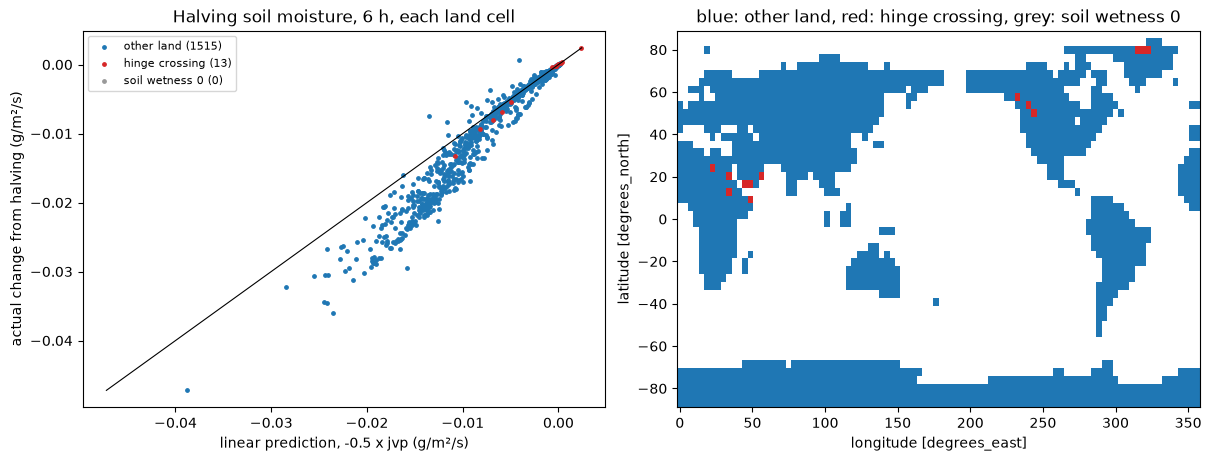

In [16]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
ax = axs[0]
for name, m, c in [("other land", other, "C0"), ("hinge crossing", crossing, "C3"), ("soil wetness 0", dry_soil, "0.6")]:
    ax.scatter(lin_half[m], fd_half[m], s=6, color=c, label=f"{name} ({m.sum()})")
lim = [min(lin_half[land].min(), fd_half[land].min()), max(lin_half[land].max(), fd_half[land].max())]
ax.plot(lim, lim, "k", lw=0.8)
ax.set(xlabel="linear prediction, -0.5 x jvp (g/m²/s)", ylabel="actual change from halving (g/m²/s)",
       title="Halving soil moisture, 6 h, each land cell")
ax.legend(fontsize=8)

cat = np.full(land.shape, np.nan)
cat[other], cat[crossing], cat[dry_soil] = 0, 1, 2
xr.DataArray(cat.T, coords={"lat": ds.lat, "lon": ds.lon}, dims=("lat", "lon")).plot(
    ax=axs[1], cmap=plt.matplotlib.colors.ListedColormap(["C0", "C3", "0.6"]), vmin=-0.5, vmax=2.5,
    add_colorbar=False)
axs[1].set(title="blue: other land, red: hinge crossing, grey: soil wetness 0")
plt.savefig("../figures/week6_task2_hinge.png", dpi=120)
plt.show()

**The hinge is not the explanation from this start.** Only 13 land cells cross it when the soil is halved, and they
account for 0.3% of the gap. No mostly-land cell has zero soil wetness on 1 January. The scatter shows the gap is in
almost every cell: the actual change lies below the 1:1 line nearly everywhere, by more where the response is large.
The cause is a smooth curvature, not a switch.

### Testing the other suspect: the skin-temperature energy balance

With `lskineb = True` (the default), SPEEDY solves for the land skin temperature from the surface energy balance
(the `lax.cond` branch in the same file). Less evaporation means less evaporative cooling, so the skin warms,
$q_{sat}(T_{skin})$ rises and evaporation partly recovers. The correction term is proportional to the wetness $w$,
so this feedback changes as the soil dries, which would make E curved in $w$. Test: rebuild the model with
`lskineb = False` (skin temperature fixed at the prescribed land temperature) and repeat the 6-hour comparison.

In [17]:
from jcm.physics.speedy.params import Parameters
from jcm.physics.speedy.speedy_terms import speedy_physics

defaults = Parameters.default()
no_skin = SpeedyModel(coords=coords, terrain=terrain, time_step=30,
                      physics=speedy_physics(defaults.replace(surface_flux=defaults.surface_flux.replace(lskineb=False))))

def evap_no_skin(soil_scale):
    forcing = bc.copy(soilw_am=bc.soilw_am.replace(values=soil_scale * bc.soilw_am.values))
    out = no_skin.run(forcing=forcing, total_time=0.25, save_interval=0.25).to_xarray()
    return out["surface_flux.evap"].isel(time=-1).data

_, t_ns = jax.jvp(evap_no_skin, (1.0,), (1.0,))
jvp_ns = land_mean(t_ns)
E0_ns = np.asarray(evap_no_skin(1.0))
print(f"{'':16s} {'jvp':>10} {'drying 1%':>10} {'drying 10%':>10} {'drying 50%':>10} {'central 50%':>11}  (ratios to jvp)")
for name, E, E0, j in [("lskineb = True", lambda s: evap_after(s, 0.25), E0_6h, jvp6),
                       ("lskineb = False", evap_no_skin, E0_ns, jvp_ns)]:
    d = [land_mean((E0 - np.asarray(E(1 - h))) / h) / j for h in (0.01, 0.1, 0.5)]
    c = land_mean((np.asarray(E(1.5)) - np.asarray(E(0.5))) / 1.0) / j
    print(f"{name:16s} {j:10.3e} {d[0]:10.3f} {d[1]:10.3f} {d[2]:10.3f} {c:11.3f}")

                        jvp  drying 1% drying 10% drying 50% central 50%  (ratios to jvp)


lskineb = True    1.466e-02      1.021      1.052      1.279       1.065


lskineb = False   7.415e-02      1.001      1.003      1.015       1.003


**The skin-temperature balance is the source of the curvature.** With `lskineb = False`, the drying ratios are 1.001,
1.003 and 1.015 for 1%, 10% and 50%: evaporation is almost linear in soil moisture, as the bulk formula says it should
be away from the hinge.

The jvp also changes a lot: 7.4e-2 without the skin balance against 1.5e-2 with it. So within 6 hours the skin
warming cancels about 80% of the direct drop in evaporation. Since the correction term scales with the wetness $w$,
this damping weakens as the soil dries, and the response to a large drying is bigger than the gradient at $w$
predicts.

## 5. Same step size: does the window matter?

Keep the step at 1% (central and drying) and at 50% (drying), and lengthen the window from 6 hours to 7 days.
The 7-day, 50% value is section 2a. Then repeat the 6-hour comparison from a spun-up state (the end of the
7-day run) instead of from rest.

In [18]:
WINDOWS = [0.25, 1, 2, 4, 7]
win = {}
for window in WINDOWS:
    t = time.time()
    tan = tangent(window)
    t_jvp = time.time() - t
    E0 = np.asarray(evap_after(1.0, window))
    up, d1, d50 = (np.asarray(evap_after(s, window)) for s in (1.01, 0.99, 0.5))
    win[window] = dict(jvp=tan, c1=(up - d1) / 0.02, d1=(E0 - d1) / 0.01, d50=(E0 - d50) / 0.5, t_jvp=t_jvp)

print("per unit soil_scale (g/m²/s); multiply by -0.01 for the response to 1% drying")
print(f"{'days':>5} {'jvp':>11} {'central 1%':>11} {'drying 1%':>11} {'drying 50%':>11}  ratios to jvp")
for window in WINDOWS:
    r = {k: land_mean(win[window][k]) for k in ("jvp", "c1", "d1", "d50")}
    print(f"{window:5} {r['jvp']:11.3e} {r['c1']:11.3e} {r['d1']:11.3e} {r['d50']:11.3e}  "
          f"{r['c1'] / r['jvp']:5.2f} {r['d1'] / r['jvp']:5.2f} {r['d50'] / r['jvp']:5.2f}")
print("2a / 50 per unit soil_scale:", f"{-land_mean(fd_2a) / 0.5:.3e} (same as the 7-day, 50% column)")

per unit soil_scale (g/m²/s); multiply by -0.01 for the response to 1% drying
 days         jvp  central 1%   drying 1%  drying 50%  ratios to jvp
 0.25   1.466e-02   1.482e-02   1.497e-02   1.875e-02   1.01  1.02  1.28
    1   1.428e-02   1.494e-02   1.504e-02   1.871e-02   1.05  1.05  1.31
    2   1.429e-02   1.475e-02   1.514e-02   1.930e-02   1.03  1.06  1.35
    4   1.392e-02   1.450e-02   1.464e-02   2.008e-02   1.04  1.05  1.44
    7   1.315e-02   1.669e-02   1.386e-02   1.804e-02   1.27  1.05  1.37
2a / 50 per unit soil_scale: 1.804e-02 (same as the 7-day, 50% column)


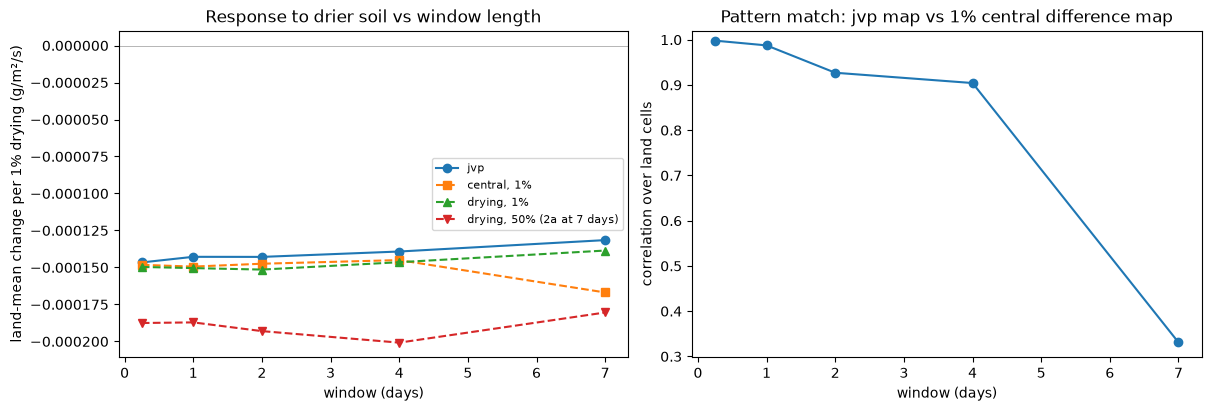

map correlations: {0.25: np.float64(0.998), 1: np.float64(0.987), 2: np.float64(0.927), 4: np.float64(0.904), 7: np.float64(0.331)}
jvp time per window (s, includes compile): {0.25: 0.2, 1: 6.7, 2: 7.5, 4: 9.2, 7: 10.7}


In [19]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for k, style, label in [("jvp", "o-", "jvp"), ("c1", "s--", "central, 1%"), ("d1", "^--", "drying, 1%"),
                        ("d50", "v--", "drying, 50% (2a at 7 days)")]:
    axs[0].plot(WINDOWS, [-0.01 * land_mean(win[w][k]) for w in WINDOWS], style, label=label)
axs[0].axhline(0, color="0.6", lw=0.5)
axs[0].set(xlabel="window (days)", ylabel="land-mean change per 1% drying (g/m²/s)",
           title="Response to drier soil vs window length")
axs[0].legend(fontsize=8)

# Pattern agreement with the 1% central difference, per window
corr = [np.corrcoef(win[w]["jvp"][land], win[w]["c1"][land])[0, 1] for w in WINDOWS]
axs[1].plot(WINDOWS, corr, "o-")
axs[1].set(xlabel="window (days)", ylabel="correlation over land cells", ylim=(None, 1.02),
           title="Pattern match: jvp map vs 1% central difference map")
plt.savefig("../figures/week6_task2_window.png", dpi=120)
plt.show()
print("map correlations:", dict(zip(WINDOWS, np.round(corr, 3))))
print("jvp time per window (s, includes compile):", {w: round(win[w]['t_jvp'], 1) for w in WINDOWS})

In [20]:
# 6 hours from a spun-up state (the end of the 7-day run) instead of from rest
ic = load_states_from_xarray(ds.isel(time=-1).sortby("level"))
tan_ic = tangent(0.25, ic)
E0_ic = np.asarray(evap_after(1.0, 0.25, ic))
up, d1, d50 = (np.asarray(evap_after(s, 0.25, ic)) for s in (1.01, 0.99, 0.5))
r = dict(jvp=land_mean(tan_ic), c1=land_mean((up - d1) / 0.02), d1=land_mean((E0_ic - d1) / 0.01),
         d50=land_mean((E0_ic - d50) / 0.5))
print(f"spun-up start, 6 h: baseline land evaporation {land_mean(E0_ic):.4f} g/m²/s (from rest: {land_mean(E0_6h):.4f})")
print(f"jvp {r['jvp']:.3e}; ratios to jvp: central 1% {r['c1'] / r['jvp']:.3f}, drying 1% {r['d1'] / r['jvp']:.3f}, "
      f"wetting 1% {land_mean((up - E0_ic) / 0.01) / r['jvp']:.3f}, drying 50% {r['d50'] / r['jvp']:.3f}")

# Where does the wetting side depart from the gradient? Cells where the gradient is exactly 0 (hinge closed:
# no land evaporation), but wetting by 1% switches evaporation on.
wet_gap = (up - E0_ic) / 0.01 - tan_ic
closed = land & (tan_ic == 0)
print(f"land cells with gradient exactly 0: {closed.sum()}; their share of the wetting-side gap: "
      f"{(wet_gap * W)[closed].sum() / (wet_gap * W)[land].sum():.0%}")

spun-up start, 6 h: baseline land evaporation 0.0154 g/m²/s (from rest: 0.0308)
jvp 2.238e-02; ratios to jvp: central 1% 1.170, drying 1% 1.037, wetting 1% 1.303, drying 50% 1.151
land cells with gradient exactly 0: 300; their share of the wetting-side gap: 102%


**From rest:**

- **Up to 4 days, the gradient tracks the 1% finite difference.** Land-mean ratios are 1.01–1.06, and map correlations
  are 0.998, 0.987, 0.93 and 0.90 at 6 h, 1, 2 and 4 days.
- **At 7 days, the 1% finite difference becomes weather noise.** The central difference jumps to 1.27× the jvp, while
  the drying-only one stays at 1.05: the +1% and −1% runs have diverged from each other. The map correlation drops to
  0.33. The land mean hides much of this because the noise averages out; the map shows it.
- **The 50% step is 1.28–1.44× the jvp at every window.** That gap is the curvature from section 4, not the window.
- **jvp cost grows with the window:** 6.7 s (1 day) to 10.7 s (7 days), including compilation. Forward mode does not
  store the run, so its memory does not grow with the window.

**From a spun-up start** (6 hours from day 7), the drying side still agrees (1.04), but **wetting by 1% gives 1.30× the
jvp**. In 300 land cells the gradient is exactly zero because the hinge is closed: the air is moister than the soil can
supply, so evaporation is 0. Wetting the soil switches evaporation on there. Those cells account for all of the
wetting-side gap. This is the switch the course page warns about. From rest it barely appears, because 6 hours after
starting from rest the air is still dry everywhere, with land evaporation twice its day-7 value.

## 6. Maps side by side

Response to 1% drying, from: 2a scaled by 1/50 (7 days, 50% step), the 7-day jvp, the 6-hour 1% central difference
and 2b (6-hour jvp).

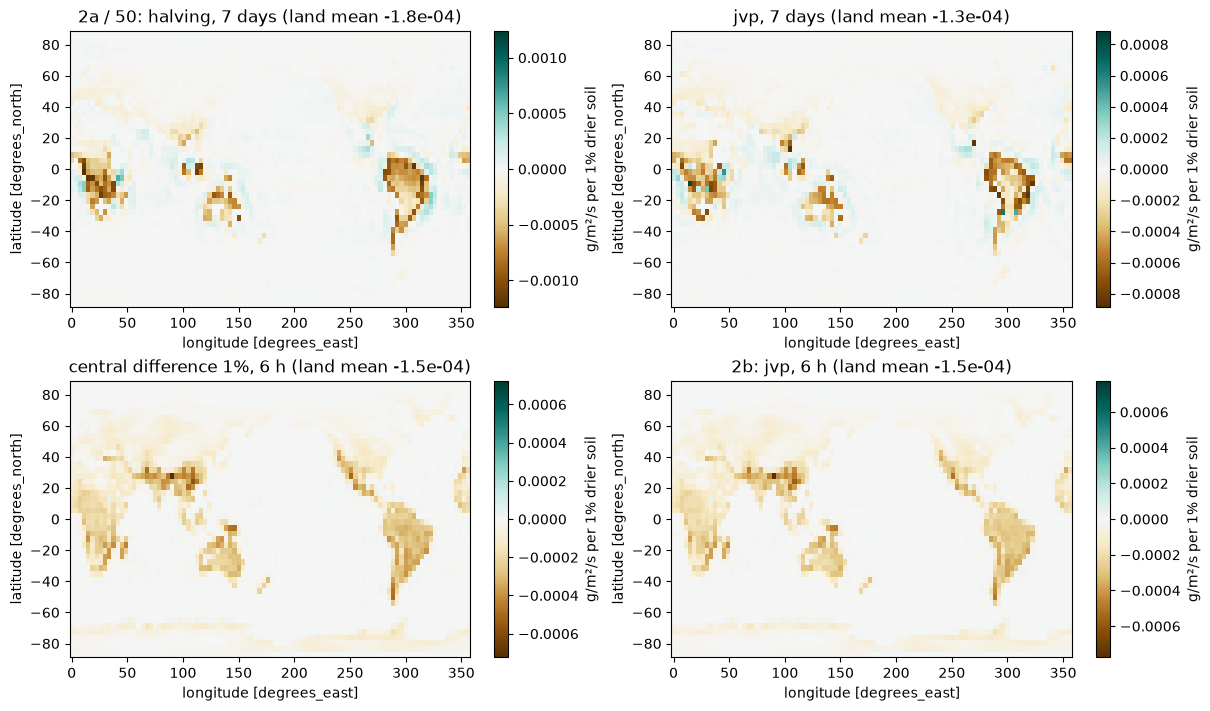

pattern correlation, 2a/50 vs 7-day jvp: 0.77
pattern correlation, 2a/50 vs 2b:        0.62
pattern correlation, 7-day vs 6-h jvp:   0.59
baseline land-mean evaporation from rest: 6 h 0.0308, 7 days 0.0148 g/m²/s


In [21]:
panels = [("2a / 50: halving, 7 days", fd_2a / 50),
          ("jvp, 7 days", -0.01 * win[7]["jvp"]),
          ("central difference 1%, 6 h", -0.01 * step[0.01]["central"]),
          ("2b: jvp, 6 h", jvp_2b)]
fig, axs = plt.subplots(2, 2, figsize=(12, 7), constrained_layout=True)
for ax, (title, m) in zip(axs.flat, panels):
    v = np.abs(m[land]).max()
    xr.DataArray(m.T, coords={"lat": ds.lat, "lon": ds.lon}, dims=("lat", "lon")).plot(
        ax=ax, cmap="BrBG", vmin=-v, vmax=v, cbar_kwargs={"label": "g/m²/s per 1% drier soil"})
    ax.set_title(f"{title} (land mean {land_mean(m):+.1e})")
plt.savefig("../figures/week6_task2_maps.png", dpi=110)
plt.show()

def pattern_corr(a, b):
    return np.corrcoef(a[land], b[land])[0, 1]
print(f"pattern correlation, 2a/50 vs 7-day jvp: {pattern_corr(fd_2a, -win[7]['jvp']):.2f}")
print(f"pattern correlation, 2a/50 vs 2b:        {pattern_corr(fd_2a, jvp_2b):.2f}")
print(f"pattern correlation, 7-day vs 6-h jvp:   {pattern_corr(win[7]['jvp'], t6):.2f}")
print(f"baseline land-mean evaporation from rest: 6 h {land_mean(E0_6h):.4f}, 7 days {land_mean(evap0_7d):.4f} g/m²/s")

In [22]:
# Save the maps and the land-mean numbers
out = xr.Dataset(
    {
        "jvp": (("window", "lon", "lat"), np.stack([win[w]["jvp"] for w in WINDOWS]),
                {"long_name": "d(evaporation)/d(soil_scale) at soil_scale = 1", "units": "g m-2 s-1"}),
        "fd_central_1pct": (("window", "lon", "lat"), np.stack([win[w]["c1"] for w in WINDOWS]),
                            {"long_name": "central difference, h = 0.01", "units": "g m-2 s-1"}),
        "fd_drying_50pct": (("window", "lon", "lat"), np.stack([win[w]["d50"] for w in WINDOWS]),
                            {"long_name": "(E(1) - E(0.5)) / 0.5", "units": "g m-2 s-1"}),
        "land": (("lon", "lat"), land),
    },
    coords={"window": ("window", WINDOWS, {"units": "days"}), "lon": ds.lon.values, "lat": ds.lat.values},
    attrs={"description": "Week 6 Task 2: evaporation response to soil-moisture scaling, start from rest on "
                          "1 January, T31 L8, jcm packaged T30 climatology. Multiply by -0.01 for 1% drying."},
)
out.to_netcdf("../results/w6-task2_soil.nc")
print(out)

<xarray.Dataset> Size: 282kB
Dimensions:          (window: 5, lon: 96, lat: 48)
Coordinates:
  * window           (window) float64 40B 0.25 1.0 2.0 4.0 7.0
  * lon              (lon) float64 768B 0.0 3.75 7.5 11.25 ... 348.8 352.5 356.2
  * lat              (lat) float64 384B -87.16 -83.48 -79.78 ... 83.48 87.16
Data variables:
    jvp              (window, lon, lat) float32 92kB 0.0 0.002282 ... 0.0002877
    fd_central_1pct  (window, lon, lat) float32 92kB 0.0 0.002224 ... 0.0001192
    fd_drying_50pct  (window, lon, lat) float32 92kB 0.0 0.002247 ... 1.653e-05
    land             (lon, lat) bool 5kB True True True ... False False False
Attributes:
    description:  Week 6 Task 2: evaporation response to soil-moisture scalin...


## Interpretation

**Why do 2a and 2b differ in size?** They answer different questions. 2a is the response to a large change over a
week; 2b is the local slope over 6 hours. Scaled to 1%, 2a is 1.23× 2b in the land mean. That factor splits into two
parts that we can measure separately:

1. **Step size (×1.37 at 7 days, ×1.28 at 6 h).** Evaporation is concave in soil moisture because of the
   skin-temperature energy balance. Drier soil warms the skin, which partly restores evaporation (80% of the direct
   response at 6 h), and this damping weakens as the soil dries. Turning the skin balance off makes the response
   linear (×1.015), which confirms the mechanism.
2. **Window (×0.90).** The 7-day gradient is 10% smaller than the 6-hour one, and its pattern is different (correlation
   0.59). By day 7 the response is concentrated on tropical and summer-hemisphere land. At 6 hours after starting from
   rest, the dry initial air makes every continent evaporate, including the winter ones.

**When to trust the gradient.** With a step small enough to be linear but well above float32 round-off (0.3–10%), the
finite difference and the jvp agree to about 1% at 6 hours and to about 5% (map correlation ≥ 0.90) up to 4 days.
They part ways at 7 days, when the finite difference itself becomes weather noise. From a realistic (spun-up) state,
the evaporation hinge adds a second gap: a gradient sees nothing in the 300 cells where evaporation is off, but a
finite difference that wets the soil switches it on.

**For course Question 2 (two reasons derivatives and finite differences differ), with evidence from this notebook:**
(1) nonlinearity over a finite step (the skin-balance curvature: ×1.28 for halving); (2) on/off switches whose
derivative is zero (the evaporation hinge from a spun-up state: wetting gives ×1.30). Two smaller ones: chaos over long
windows (7 days), and float32 round-off for very small steps (h = 0.001).

**Not checked:** whether `evap_smoothing > 0` closes the hinge gap from the spun-up start; only one start date
(1 January); land means weight cells by cos(lat) only, not by land fraction.